# 实践 1：鸢尾花（Iris）数据集 PCA 降维 —— 逐行注释 + 跑通版

> 原始文件：`pca降维.ipynb`（课程给出）
>
> 本文件保留原始实现的**全部逻辑、函数名与调用顺序**，只做了三件事：
>
> 1. **逐行加注释**：说明每一句「在做什么」以及「对应哪个数学公式」；
> 2. **修掉在 NumPy 2.x 下会直接报错的写法**（`np.mat` 已在 NumPy 2.0 中被移除），并说明原因与替代方案；
> 3. **把每一步的中间量打印/画出来**，方便与手算结果对照，也方便验证「降维到底丢了多少信息」。

---

## 一、实验目标

不使用 `sklearn.decomposition.PCA`，而是**从零手写 PCA**，把 4 维的鸢尾花特征降到 2 维，
再反投影回 4 维，观察：

- 每个主成分保留了百分之多少的方差；
- 降到 2 维后，3 个类别是否仍然可分；
- 重构误差（信息损失）有多大。

## 二、数据

`sklearn.datasets.load_iris()`（Fisher 1936 经典数据集，随 scikit-learn 一起分发，无需联网）：

| 项目 | 说明 |
| --- | --- |
| 样本数 | 150 |
| 特征数 | 4：花萼长 sepal length、花萼宽 sepal width、花瓣长 petal length、花瓣宽 petal width（单位 cm） |
| 类别 | 3：setosa / versicolor / virginica，各 50 个 |
| 用途 | 特征矩阵 `data` 用于 PCA；类别 `target` **只用于给散点上色**，绝不参与降维（PCA 是无监督的） |

## 三、PCA 的六步（原始 notebook 顶部给出的流程，以及本文件对应的代码位置）

| 步骤 | 数学操作 | 本文件对应位置 |
| --- | --- | --- |
| 0. 取数据 | $X \in \mathbb{R}^{150\times4}$ | `loadIris()` |
| 1. 组织成「列 = 样本，行 = 维度」 | 转置 | 现代写法直接用 `(n_samples, n_features)`，见第 4 章说明 |
| 2. 零均值化 | $x' = x-\bar{x}$，按列减均值 | `stand_data()` |
| 3. 求协方差矩阵 | $C=\frac{1}{n-1}X'^\top X'$ | `getCovMat()` |
| 4. 特征分解 | $C v = \lambda v$ | `getFValueAndFVector()` |
| 5. 取前 k 个特征向量组成 $P$ | 按 $\lambda$ 从大到小排序，取前 k 列 | `getVectorMatrix()` |
| 6. 投影得到 k 维数据 | $Y = X' P$ | `getResult()` |
| 7. 反投影（重构） | $\hat X = Y P^\top + \bar{x}$ | 驱动代码里的 `recon` |

## 四、运行环境

```
Python 3.13 / numpy 2.3 / scikit-learn 1.9 / matplotlib 3.11
```

执行方式（在本目录下）：

```bash
jupyter nbconvert --to notebook --execute --inplace "01_鸢尾花PCA_注释版.ipynb"
# 或者直接 jupyter lab / notebook 打开后「全部运行」
```

## 五、目录

1. 环境准备
2. 原始代码（原样贴出）+ 问题标注
3. 注释版实现（含驱动代码，先复现原始输出）
4. 逐步拆解：每一步的中间量 + 数学验证
5. 可视化：原版图的歧义 → 修正版三张图
6. 与 `sklearn` 的 PCA 交叉验证
7. 结论 + 踩坑清单

# 1. 环境准备

只导入三种东西：`numpy`（数值计算）、`matplotlib`（画图）、`sklearn.datasets`（拿数据集）。
PCA 本身**完全手写**，不调用 `sklearn.decomposition.PCA`（只在第 6 章做交叉验证时用一下）。

In [1]:
# ==================== 1. 环境准备 ====================
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn import datasets

# --- 中文显示：Windows 下用微软雅黑/黑体，否则图里的中文会变成方框 ---
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False        # 负号正常显示（否则是方块）
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

np.set_printoptions(precision=4, suppress=True, linewidth=120)
np.random.seed(42)                                # 让抖动/随机数可复现

import os
os.makedirs("images", exist_ok=True)              # 图保存目录

print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
import sklearn
print("scikit-learn:", sklearn.__version__)

numpy      : 2.3.3
matplotlib : 3.11.2
scikit-learn: 1.9.1


# 2. 原始代码（原样贴出）+ 问题标注

先把课程给的原始 cell 原封不动贴出来，方便逐行对照本文件的注释版：

```python
from sklearn import datasets
import numpy as np
import matplotlib.pyplot as plt

class PCAtest():
    def __init__(self, k):
        self.k = k

    def loadIris(self):
        data = datasets.load_iris()["data"]
        return data

    def stand_data(self, data):
        mean_vector = np.mean(data, axis=0)
        return mean_vector, data - mean_vector

    def getCovMat(self, standData):
        return np.cov(standData, rowvar=0)

    def getFValueAndFVector(self, covMat):
        fValue, fVector = np.linalg.eig(covMat)
        return fValue, fVector

    def getVectorMatrix(self, fValue, fVector):
        fValueSort = np.argsort(-fValue)
        fValueTopN = fValueSort[:self.k]
        return fVector[:, fValueTopN]

    def getResult(self, data, vectorMat):
        return np.dot(data, vectorMat)

def show_picture(dataMat, reconMat):
    fig = plt.figure()
    ax = fig.add_subplot(111)
    ax.scatter(dataMat[:, 0].flatten(), dataMat[:, 1].flatten(), marker='s', s=90, c='gray', label='Original Data')
    ax.scatter(reconMat[:, 0].flatten(), reconMat[:, 1].flatten(), marker='s', s=50, c='black', label='Reconstructed Data')
    plt.legend()
    plt.show()

if __name__ == "__main__":
    pca = PCAtest(2)
    data = pca.loadIris()

    (mean_vector, standdata) = pca.stand_data(data)
    print("均值向量为：%s \n" % mean_vector)
    cov_mat = pca.getCovMat(standdata)
    print("协方差矩阵:\n%s" % cov_mat)
    fvalue, fvector = pca.getFValueAndFVector(cov_mat)
    print("特征值为：%s\n特征向量为：\n%s" % (fvalue, fvector))
    fvectormat = pca.getVectorMatrix(fvalue, fvector)
    print("最终需要的特征向量：\n%s" % fvector)
    newdata = pca.getResult(standdata, fvectormat)

    print("最终重构结果为:\n{}".format(np.mat(newdata) * fvectormat.T + mean_vector))

    show_picture(standdata, newdata)
```

## 逐条标注出的 6 个问题

| # | 位置 | 问题 | 说明 / 修改方式 |
| --- | --- | --- | --- |
| 1 | `np.mat(newdata)` | **直接崩溃**：`AttributeError: module 'numpy' has no attribute 'mat'`。`np.mat`/`np.matrix` 类型在 NumPy 2.0（2024-06）被移除 | 改用 `@` 或 `np.dot`：`newdata @ fvectormat.T + mean_vector`。`np.matrix` 是「二维矩阵专用」的老类型，会把 1 维数组偷偷变成 2 维 `(1,n)`，坑很多，官方建议永远用 `ndarray` + `@` |
| 2 | `print("最终需要的特征向量：\n%s" % fvector)` | 打印的是**完整 4×4** 特征向量矩阵，不是取出来的前 k 个（`fvectormat`），所以输出里「最终需要的特征向量」和「特征向量为」一模一样，容易让人误以为 k 没生效 | 改成打印 `fvectormat`（4×2） |
| 3 | `show_picture(standdata, newdata)` | 把**两个不同空间**的坐标叠在一张图上：灰方是「中心化后的原始 4 维数据的前两维（花萼长/宽）」，黑方是「PCA 投影后的 PC1/PC2」。两个坐标系毫无共同刻度，这张图只能说明「点的个数一样」，**说明不了降维效果** | 第 5 章给出有意义的修正版：PCA 图上按真实类别上色 + 双标图（biplot）；另加碎石图、重构误差曲线 |
| 4 | `np.cov(standData, rowvar=0)` | 数据已经是 `(150, 4)`，`rowvar=0` 表示「每一列是一个变量」→ 得到 4×4 协方差矩阵，**正确**。但如果误写成默认的 `rowvar=1`，会得到 150×150 的样本间协方差，既慢又没意义 | 保留原写法，注释里强调这个开关 |
| 5 | `np.linalg.eig(covMat)` | 求出的特征值**顺序是任意的**（不是从大到小），所以后面必须排序；且 `eig` 对数值上近似对称的矩阵可能返回复数 dtype（虚部≈0） | 保留原写法，但补一句 `np.linalg.eigh`（对称矩阵专用，实数、升序、更稳）作为推荐 |
| 6 | `stand_data` 只做「零均值化」，没有「标准化」 | 名字叫 `stand_data` 但实际只是 centering。鸢尾花 4 个特征量纲相同（cm）且方差量级相近，影响不大；换一批量纲不同的数据，PCA 会被方差最大的特征「绑架」 | 保留原逻辑，并在第 7 章说明什么时候必须 `/ std` |

In [2]:
# ============================================================================
# 3. 注释版实现（结构、函数名、调用顺序与原版完全一致）
#
#    每一段注释都标注：这一步「在做什么」↔「对应哪个数学公式」
# ============================================================================
import numpy as np
from sklearn import datasets


class PCAtest():
    '''手写 PCA（主成分分析）演示类。

    参数
    ----
    k : int
        目标维度，即保留几个主成分。

    说明
    ----
    这里只做「零均值化」（centering），**不做**「除以标准差」（standardization），
    与原始代码保持一致。对鸢尾花（4 个特征都是 cm、量级相近）没有问题；
    若各特征量纲差异大（例如「元」和「米」），必须先标准化，否则：
      - 方差大的特征会垄断第一主成分；
      - 特征向量会被量纲「扭曲」，难以解释。
    '''

    def __init__(self, k):
        # 目标维度 k：把 4 维压到 k 维（本例 k=2）
        self.k = k

    # ------------------------------------------------------------------
    # 第 0 步：取数据
    # ------------------------------------------------------------------
    def loadIris(self):
        '''取出鸢尾花数据集的「特征矩阵」作为 PCA 的原始数据。

        load_iris() 返回一个 Bunch（可以当字典用）：
            data          : ndarray (150, 4) 特征矩阵
            target        : ndarray (150,)   类别标签 0/1/2
            target_names  : ['setosa', 'versicolor', 'virginica']
            feature_names : ['sepal length (cm)', ..., 'petal width (cm)']

        注意：PCA 是无监督的，降维过程**只使用 data，不使用 target**。
              target 只在画图时用来给点上色。
        '''
        data = datasets.load_iris()["data"]      # 等价于 load_iris().data
        return data                             # (150, 4)

    # ------------------------------------------------------------------
    # 第 1~2 步：零均值化（centering）
    #     公式：x' = x - mean(x)，对「每一列」减该列均值
    # ------------------------------------------------------------------
    def stand_data(self, data):
        '''对每一列（每个特征）减去该列均值，使每列均值变为 0。

        np.mean(data, axis=0) 的含义：
            axis=0 → 沿着「行」的方向做压缩，对每一列求平均
            形状变化：(150, 4) --mean(axis=0)--> (4,)   4 个特征的均值向量

        data - mean_vector 用到了 NumPy 的「广播」(broadcasting)：
            (150, 4) - (4,)  →  (150, 4)
            即每一行都减去同一个均值向量，不会有任何显式循环。

        为什么要零均值化？
            协方差公式 C = 1/(n-1) · Σ (x_i-μ)(x_i-μ)^T 本身就是围绕均值算的。
            不先减掉均值，np.cov 内部也会替你减（见第 4.3 节实验），
            但先减掉可以保证「投影后的主成分得分」也是零均值的，
            重构时才能用 X̂ = Y·P^T + μ 一步加回来。
        '''
        mean_vector = np.mean(data, axis=0)      # (4,)   每个特征的均值
        return mean_vector, data - mean_vector   # (4,) 和 (150, 4) 中心化后的数据

    # ------------------------------------------------------------------
    # 第 3 步：协方差矩阵
    #     C[i][j] = 特征 i 与特征 j 的协方差，C[i][i] = 特征 i 的方差
    #     公式：C = X'^T X' / (n-1)
    # ------------------------------------------------------------------
    def getCovMat(self, standData):
        '''求 4×4 的协方差矩阵。

        np.cov 的关键参数 rowvar：
            rowvar=0 → 每一「列」是一个变量（我们这里 4 列 = 4 个特征）→ 4×4   ✅
            rowvar=1 → 每一「行」是一个变量（默认值）→ 会得到 150×150 的样本间协方差  ❌

        其它参数：
            ddof=1（默认）→ 除以 n-1，样本协方差（无偏估计）
            ddof=0 / bias=True → 除以 n，总体协方差
        协方差矩阵一定是对称半正定的，因此它的特征值 ≥ 0，
        特征向量两两正交 —— 这是 PCA 能「用一组正交方向重新描述数据」的理论基础。
        '''
        return np.cov(standData, rowvar=0)       # (4, 4)，对角元是各特征方差

    # ------------------------------------------------------------------
    # 第 4 步：特征分解
    #     求解 C v = λ v：λ 是特征值（方差大小），v 是对应的特征向量（主成分方向）
    # ------------------------------------------------------------------
    def getFValueAndFVector(self, covMat):
        '''返回 (特征值数组, 特征向量矩阵)。

        np.linalg.eig(A) 返回 (w, v)：
            w : (4,)   特征值，**顺序任意**，不保证从大到小
            v : (4, 4) 特征向量，**按列存放** —— 第 i 列是 w[i] 对应的特征向量
                （这一点极易写错：很多人会当成「按行」，结果取到的是别的方向）

        两个必须知道的性质：
            1. 特征向量已经归一化（长度为 1），无需再除以范数；
            2. 特征向量的「符号」不唯一：v 和 -v 都是合法的，
               所以本例结果与 sklearn 的结果可能整体差一个负号，这不影响投影质量。
        '''
        fValue, fVector = np.linalg.eig(covMat)
        return fValue, fVector

    # ------------------------------------------------------------------
    # 第 5 步：按特征值从大到小排序，取前 k 个特征向量，组成投影矩阵 P
    # ------------------------------------------------------------------
    def getVectorMatrix(self, fValue, fVector):
        '''返回 P = 前 k 个最大特征值对应的特征向量，形状 (4, k)。

        np.argsort(-fValue)：先取负号再升序排列，等价于对原值降序排列，
            返回的是**下标**而不是数值。
            例：fValue = [2.9, 0.9, 0.15, 0.02]
                -fValue 升序 → 原值降序 → 下标 [0, 2, 1, 3] 之类的顺序

        fVector[:, idx] 用「整数数组下标」同时取多列，得到 (4, k)。
        '''
        fValueSort = np.argsort(-fValue)         # 特征值降序排列后的下标 (4,)
        fValueTopN = fValueSort[:self.k]         # 取前 k 个下标     (k,)
        return fVector[:, fValueTopN]            # 按列取 → 投影矩阵 P (4, k)

    # ------------------------------------------------------------------
    # 第 6 步：投影
    #     Y = X' · P，形状 (150, 4) @ (4, k) = (150, k)
    #     Y 的第 j 列就是「第 j 个主成分得分」，它的样本方差恰好等于第 j 个特征值
    # ------------------------------------------------------------------
    def getResult(self, data, vectorMat):
        '''把中心化后的数据投影到 k 个主成分方向上。

        np.dot(A, B) 与 A @ B 完全等价（二维情况下）。
        注意：* 是逐元素相乘，矩阵乘法一定要用 @ / np.dot / np.matmul。
        '''
        return np.dot(data, vectorMat)           # (150, 4) @ (4, k) = (150, k)


def show_picture(dataMat, reconMat):
    '''原版的画图函数（原样保留，用于第 5 章对比）。

    参数 dataMat  : 中心化后的原始数据 (150, 4)，只用到前两列 = 花萼长/宽
    参数 reconMat : PCA 投影后的数据 (150, 2) = PC1/PC2
    两者坐标系不同，叠在一起没有可比性 —— 见第 5 章的说明与修正版。
    '''
    fig = plt.figure(figsize=(6, 4.5))
    ax = fig.add_subplot(111)                 # 111 = 1 行 1 列第 1 个子图
    # 灰方块：原始空间的前两维（中心化后的花萼长 / 花萼宽）
    ax.scatter(dataMat[:, 0].flatten(), dataMat[:, 1].flatten(),
               marker='s', s=90, c='gray', label='Original Data')
    # 黑方块：降维后的两维（PC1 / PC2）
    ax.scatter(reconMat[:, 0].flatten(), reconMat[:, 1].flatten(),
               marker='s', s=50, c='black', label='Reconstructed Data')
    ax.set_title("原版 show_picture：两个不同空间叠在一张图上")
    plt.legend()
    plt.savefig("images/01_original_show_picture.png", dpi=140, bbox_inches="tight")
    plt.show()

# 3. 注释版实现

下面这一格是完整的 `PCAtest` 类：**逻辑、函数名、调用顺序与原始代码完全一致**，
只在注释里补齐了「数学含义 + 参数陷阱 + 为什么这么写」。

读代码时可以按这个顺序对照：

```
loadIris()            →  取 X (150,4)
stand_data()          →  μ, X' = X-μ          （第 2 步）
getCovMat()           →  C = X'ᵀX'/(n-1)      （第 3 步）
getFValueAndFVector() →  C v = λ v            （第 4 步）
getVectorMatrix()     →  P = v[:, 前k大]      （第 5 步）
getResult()           →  Y = X' P             （第 6 步）
重构                   →  X̂ = Y Pᵀ + μ        （第 7 步，原代码在 main 里做）
```
要注意：`show_picture` 用到了 `plt`，所以它依赖下一格（驱动代码）里导入的 matplotlib，
这里故意不在类定义处 import，方便单独阅读。

均值向量为：[5.8433 3.0573 3.758  1.1993] 

协方差矩阵:
[[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]
特征值为：[4.2282 0.2427 0.0782 0.0238]
特征向量为：
[[ 0.3614 -0.6566 -0.582   0.3155]
 [-0.0845 -0.7302  0.5979 -0.3197]
 [ 0.8567  0.1734  0.0762 -0.4798]
 [ 0.3583  0.0755  0.5458  0.7537]]
最终需要的特征向量（4×2，原版这里误打印成了 4×4 的 fvector）：
[[ 0.3614 -0.6566]
 [-0.0845 -0.7302]
 [ 0.8567  0.1734]
 [ 0.3583  0.0755]]
降维后的数据形状： (150, 2)
最终重构结果为:
[[5.083  3.5174 1.4032 0.2135]
 [4.7463 3.1575 1.4636 0.2402]
 [4.7041 3.1957 1.3082 0.1752]
 [4.6422 3.057  1.4613 0.2397]
 [5.0718 3.5266 1.3637 0.197 ]
 [5.5058 3.7914 1.6755 0.3262]
 [4.7653 3.2304 1.3572 0.1955]
 [5.0016 3.3986 1.4799 0.2461]
 [4.4205 2.879  1.3856 0.2088]
 [4.8027 3.2002 1.4881 0.2503]
 [5.3609 3.7402 1.4985 0.2524]
 [4.9088 3.2889 1.5172 0.2621]
 [4.6821 3.1212 1.412  0.2188]
 [4.3425 2.9564 1.0849 0.0829]
 [5.6615 4.1416 1.288  0.1628]
 [5.8596 4.236  1.482

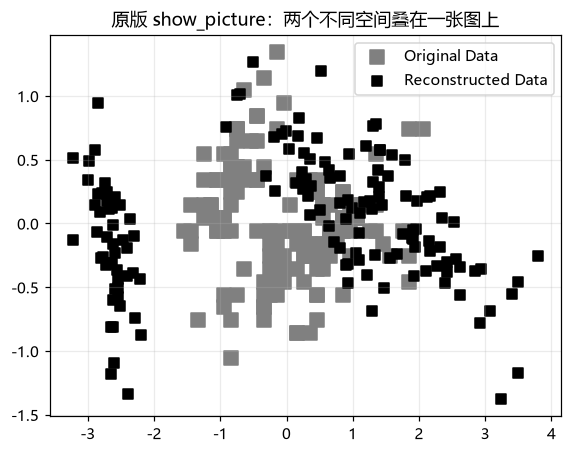

In [3]:
# ============================================================================
# 4. 驱动代码：按原 notebook 的顺序跑一遍，复现原始输出
# ============================================================================
pca = PCAtest(2)                              # 目标：降到 2 维
data = pca.loadIris()                         # (150, 4)

# --- 第 1~2 步：零均值化 ---
(mean_vector, standdata) = pca.stand_data(data)
print("均值向量为：%s \n" % mean_vector)

# --- 第 3 步：协方差矩阵 ---
cov_mat = pca.getCovMat(standdata)
print("协方差矩阵:\n%s" % cov_mat)

# --- 第 4 步：特征分解 ---
fvalue, fvector = pca.getFValueAndFVector(cov_mat)
print("特征值为：%s\n特征向量为：\n%s" % (fvalue, fvector))

# --- 第 5 步：取前 k 个特征向量组成 P ---
fvectormat = pca.getVectorMatrix(fvalue, fvector)
print("最终需要的特征向量（4×2，原版这里误打印成了 4×4 的 fvector）：\n%s" % fvectormat)

# --- 第 6 步：投影到 2 维 ---
newdata = pca.getResult(standdata, fvectormat)
print("降维后的数据形状：", newdata.shape)

# --- 第 7 步：反投影（重构）X̂ = Y·P^T + μ ---
# 原写法：np.mat(newdata) * fvectormat.T + mean_vector
# np.mat 在 NumPy 2.0 已被移除，用 @ 代替（数学上完全等价）
recon = newdata @ fvectormat.T + mean_vector
print("最终重构结果为:\n{}".format(recon))

# --- 原版画图（有歧义，第 5 章解释并修正）---
show_picture(standdata, newdata)

# 4. 逐步拆解：每一步的中间量 + 数学验证

前面把整条流程跑通了，但「能跑」不等于「懂了」。这一章把每一步单独拎出来，
一边打印中间量、一边用 `np.allclose` 做数学校验 —— 只要有一个 `False`，
就说明这一环实现错了。

| 小节 | 校验内容 |
| --- | --- |
| 4.1 | 数据形状、每列均值/标准差 |
| 4.2 | 中心化后每列均值是否真的为 0 |
| 4.3 | `np.cov` 与手算 `X'ᵀX'/(n-1)` 是否一致；`rowvar` 的影响 |
| 4.4 | 特征值/特征向量是否满足 `C v = λ v`；向量长度是否 1；是否两两正交 |
| 4.5 | 排序与贡献率：k=2 保留了多少信息 |
| 4.6 | 投影后各主成分的方差是否等于对应特征值 |
| 4.7 | 重构误差（SSE / RMSE / 保留方差比） |

In [4]:
# ---------- 4.1 加载并检视数据 ----------
iris = datasets.load_iris()
X = iris.data                                  # (150, 4) 特征
y = iris.target                                # (150,)   类别 0/1/2，只用于画图

print("X.shape =", X.shape, "  X.dtype =", X.dtype)
print("特征名 :", iris.feature_names)
print("类别名 :", list(iris.target_names))
print("每类样本数 :", np.bincount(y))
print("\n前 5 行数据:\n", X[:5])
print("\n每列均值   :", X.mean(axis=0))
print("每列标准差 :", X.std(axis=0, ddof=1), "  ← 量级相近（cm），所以本例不做标准化影响不大")

import matplotlib.pyplot as plt
import matplotlib

# 中文字体：Windows 下用微软雅黑 / 黑体，否则图里的中文会变成方框
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False     # 让负号正常显示，而不是方块
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
np.set_printoptions(precision=4, suppress=True, linewidth=120)
np.random.seed(42)
print("\nmatplotlib", matplotlib.__version__, "OK")

import os
os.makedirs("images", exist_ok=True)

X.shape = (150, 4)   X.dtype = float64
特征名 : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
类别名 : [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
每类样本数 : [50 50 50]

前 5 行数据:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

每列均值   : [5.8433 3.0573 3.758  1.1993]
每列标准差 : [0.8281 0.4359 1.7653 0.7622]   ← 量级相近（cm），所以本例不做标准化影响不大

matplotlib 3.11.2 OK


In [5]:
# ---------- 4.2 中心化：验证「每列均值为 0」 ----------
mu = X.mean(axis=0)            # (4,)
Xc = X - mu                    # 广播：(150,4) - (4,)

print("均值向量 mu        =", mu)
print("中心化后每列均值   =", Xc.mean(axis=0), " ← 全是 0（浮点误差级别）")
print("校验 np.allclose   :", np.allclose(Xc.mean(axis=0), 0))
print("中心化不改变方差   :", np.allclose(Xc.var(axis=0, ddof=1), X.var(axis=0, ddof=1)))

# 教学彩蛋：中心化 = 左乘「去均值矩阵」H = I - (1/n)·11ᵀ，H 是幂等矩阵（H·H = H）
# 这也解释了为什么「中心化两次」和「中心化一次」结果一样。
n = X.shape[0]
H = np.eye(n) - np.ones((n, n)) / n
print("H @ X 与 Xc 一致   :", np.allclose(H @ X, Xc))
print("H 幂等 (H@H == H)  :", np.allclose(H @ H, H))

均值向量 mu        = [5.8433 3.0573 3.758  1.1993]
中心化后每列均值   = [-0. -0. -0. -0.]  ← 全是 0（浮点误差级别）
校验 np.allclose   : True
中心化不改变方差   : True
H @ X 与 Xc 一致   : True
H 幂等 (H@H == H)  : True


In [6]:
# ---------- 4.3 协方差矩阵：np.cov 与手算对照 ----------
cov_np = np.cov(Xc, rowvar=0)                      # numpy 写法，(4,4)
cov_manual = Xc.T @ Xc / (Xc.shape[0] - 1)         # 手算 C = X'ᵀX' / (n-1)

print("np.cov(Xc, rowvar=0):\n", cov_np)
print("\n手算 X'ᵀX'/(n-1):\n", cov_manual)
print("\n两者一致           :", np.allclose(cov_np, cov_manual))
print("矩阵是否对称       :", np.allclose(cov_np, cov_np.T))
print("对角元 = 各列方差  :", np.allclose(np.diag(cov_np), Xc.var(axis=0, ddof=1)))

# 坑 1：np.cov 内部会自动去均值，所以对「没中心化」的数据直接算，结果也一样
print("\nnp.cov(X) 与 np.cov(Xc) 一致（np.cov 自己会中心化）:",
      np.allclose(np.cov(X, rowvar=0), cov_np))

# 坑 2：rowvar 开关写反 → 得到 150×150 的「样本间」协方差，完全不是我们要的东西
print("rowvar=1 的形状（错误用法）:", np.cov(Xc, rowvar=1).shape)

# 坑 3：ddof 决定除以 n-1 还是 n，只影响整体缩放，不影响特征向量的方向
print("ddof=0 与 ddof=1 的比例（应为 n-1/n = %.4f）:" % ((n - 1) / n),
      np.allclose(np.cov(Xc, rowvar=0, ddof=0) / cov_np, (n - 1) / n))

np.cov(Xc, rowvar=0):
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]

手算 X'ᵀX'/(n-1):
 [[ 0.6857 -0.0424  1.2743  0.5163]
 [-0.0424  0.19   -0.3297 -0.1216]
 [ 1.2743 -0.3297  3.1163  1.2956]
 [ 0.5163 -0.1216  1.2956  0.581 ]]

两者一致           : True
矩阵是否对称       : True
对角元 = 各列方差  : True

np.cov(X) 与 np.cov(Xc) 一致（np.cov 自己会中心化）: True
rowvar=1 的形状（错误用法）: (150, 150)
ddof=0 与 ddof=1 的比例（应为 n-1/n = 0.9933）: True


In [7]:
# ---------- 4.4 特征分解：验证 C v = λ v、单位化、正交性 ----------
eigval, eigvec = np.linalg.eig(cov_np)

print("特征值（顺序任意！）:\n", eigval)
print("特征值 dtype：", eigval.dtype, " 虚部最大绝对值：", np.abs(np.imag(eigval)) if np.iscomplexobj(eigval) else 0.0)
print("\n特征向量矩阵（**每一列**对应一个特征值）:\n", eigvec)

# 验证 1：每个特征向量的长度都是 1
print("\n列向量长度            :", np.linalg.norm(eigvec, axis=0), " 全部为 1:", np.allclose(np.linalg.norm(eigvec, axis=0), 1))

# 验证 2：特征向量两两正交 → VᵀV = I（协方差矩阵对称带来的性质）
print("VᵀV == I              :", np.allclose(eigvec.T @ eigvec, np.eye(4)))

# 验证 3：逐列验证 C v = λ v
for i in range(4):
    lhs = cov_np @ eigvec[:, i]
    rhs = eigval[i] * eigvec[:, i]
    print(f"  第 {i} 列: C·v == λ·v ?", np.allclose(lhs, rhs))

# 推荐写法：对称矩阵用 eigh —— 结果一定是实数、按升序返回、数值更稳
w_asc, V = np.linalg.eigh(cov_np)
print("\neigh 返回的升序特征值 :", w_asc)
print("与 eig 的结果集合一致 :", np.allclose(np.sort(np.real(eigval)), w_asc))
print("eigh 的特征向量也是单位正交的:", np.allclose(V.T @ V, np.eye(4)))

特征值（顺序任意！）:
 [4.2282 0.2427 0.0782 0.0238]
特征值 dtype： float64  虚部最大绝对值： 0.0

特征向量矩阵（**每一列**对应一个特征值）:
 [[ 0.3614 -0.6566 -0.582   0.3155]
 [-0.0845 -0.7302  0.5979 -0.3197]
 [ 0.8567  0.1734  0.0762 -0.4798]
 [ 0.3583  0.0755  0.5458  0.7537]]

列向量长度            : [1. 1. 1. 1.]  全部为 1: True
VᵀV == I              : True
  第 0 列: C·v == λ·v ? True
  第 1 列: C·v == λ·v ? True
  第 2 列: C·v == λ·v ? True
  第 3 列: C·v == λ·v ? True

eigh 返回的升序特征值 : [0.0238 0.0782 0.2427 4.2282]
与 eig 的结果集合一致 : True
eigh 的特征向量也是单位正交的: True


In [8]:
# ---------- 4.5 排序 + 取 top-k：k=2 保留了多少信息？ ----------
order = np.argsort(-eigval)              # 降序排列，返回「下标」
vals = eigval[order]                     # 特征值降序
ratio = vals / vals.sum()                # 单个主成分的方差贡献率
cum = np.cumsum(ratio)                   # 累计贡献率

print("降序下标 order       :", order)
print("特征值（降序）       :", vals)
print("单个贡献率           :", ratio, " = ", np.round(ratio * 100, 2), "%")
print("累计贡献率           :", cum, " = ", np.round(cum * 100, 2), "%")
print(f"\n降到 k=2 保留的信息量 : {cum[1]*100:.4f}%   （丢掉 {100-cum[1]*100:.4f}%）")

k = 2
P = eigvec[:, order[:k]]                 # 投影矩阵 (4, 2)
print(f"\n投影矩阵 P（{P.shape[0]}×{P.shape[1]}，每列一个主成分方向）:\n", P)
print("\n各主成分最主要的特征（按 |载荷| 排序，绝对值越大说明该特征越重要）:")
for j in range(k):
    idx = np.argsort(-np.abs(P[:, j]))
    top = ", ".join(f"{iris.feature_names[i].replace(' (cm)', '')}={P[i, j]:+.3f}" for i in idx)
    print(f"  PC{j+1}: {top}")

降序下标 order       : [0 1 2 3]
特征值（降序）       : [4.2282 0.2427 0.0782 0.0238]
单个贡献率           : [0.9246 0.0531 0.0171 0.0052]  =  [92.46  5.31  1.71  0.52] %
累计贡献率           : [0.9246 0.9777 0.9948 1.    ]  =  [ 92.46  97.77  99.48 100.  ] %

降到 k=2 保留的信息量 : 97.7685%   （丢掉 2.2315%）

投影矩阵 P（4×2，每列一个主成分方向）:
 [[ 0.3614 -0.6566]
 [-0.0845 -0.7302]
 [ 0.8567  0.1734]
 [ 0.3583  0.0755]]

各主成分最主要的特征（按 |载荷| 排序，绝对值越大说明该特征越重要）:
  PC1: petal length=+0.857, sepal length=+0.361, petal width=+0.358, sepal width=-0.085
  PC2: sepal width=-0.730, sepal length=-0.657, petal length=+0.173, petal width=+0.075


In [9]:
# ---------- 4.6 投影：Y = X'·P ----------
Y = Xc @ P                               # (150,4) @ (4,2) = (150,2)
Y_hat = standdata @ fvectormat           # 用第 3 章 PCAtest 类的结果做对照

print("Y.shape =", Y.shape)
print("前 3 个样本的主成分得分:\n", Y[:3])
print("\n与 PCAtest.getResult() 的结果完全一致:", np.allclose(Y, Y_hat))

# 关键性质：投影后第 j 个主成分的「样本方差」= 第 j 个特征值
print("\n各主成分得分方差:", Y.var(axis=0, ddof=1))
print("对应特征值      :", vals[:k])

# 投影后各主成分之间「互不相关」→ 协方差矩阵近似对角
print("\nY 的协方差矩阵（应是对角阵）:\n", np.cov(Y, rowvar=0))
print("与 diag(λ) 一致:", np.allclose(np.cov(Y, rowvar=0), np.diag(vals[:k])))
print("相关系数（应为 0）:", np.corrcoef(Y, rowvar=0)[0, 1])

Y.shape = (150, 2)
前 3 个样本的主成分得分:
 [[-2.6841 -0.3194]
 [-2.7141  0.177 ]
 [-2.889   0.1449]]

与 PCAtest.getResult() 的结果完全一致: True

各主成分得分方差: [4.2282 0.2427]
对应特征值      : [4.2282 0.2427]

Y 的协方差矩阵（应是对角阵）:
 [[ 4.2282 -0.    ]
 [-0.      0.2427]]
与 diag(λ) 一致: True
相关系数（应为 0）: -2.353885439931905e-16


In [10]:
# ---------- 4.7 重构：X̂ = Y·Pᵀ + μ，以及信息损失 ----------
Xhat = Y @ P.T + mu
err = X - Xhat
sse = (err ** 2).sum()                                   # 残差平方和
sst = ((X - X.mean(axis=0)) ** 2).sum()                  # 总平方和
print("与第 3 章的重构结果一致:", np.allclose(Xhat, recon))
print(f"SSE（残差平方和）        = {sse:.6f}")
print(f"SST（总平方和）          = {sst:.6f}")
print(f"保留方差占比 1-SSE/SST   = {1 - sse / sst:.6f}  （约等于 k=2 的累计贡献率 {cum[1]:.6f}）")

print("\n各特征的 RMSE（重构误差，单位 cm）:")
for name, e in zip(iris.feature_names, np.sqrt((err ** 2).mean(axis=0))):
    print(f"  {name:24s} {e:.6f}")

print("\n单样本误差最大的 3 个（重建后偏差最大的样本，通常落在两类交界处）:")
worst = np.argsort(-(err ** 2).sum(axis=1))[:3]
for i in worst:
    print(f"  样本{i:3d} 类别={iris.target_names[y[i]]:11s} 误差平方和={((err[i])**2).sum():.4f}")

与第 3 章的重构结果一致: True
SSE（残差平方和）        = 15.204644
SST（总平方和）          = 681.370600
保留方差占比 1-SSE/SST   = 0.977685  （约等于 k=2 的累计贡献率 0.977685）

各特征的 RMSE（重构误差，单位 cm）:
  sepal length (cm)        0.169334
  sepal width (cm)         0.173763
  petal length (cm)        0.076830
  petal width (cm)         0.191295

单样本误差最大的 3 个（重建后偏差最大的样本，通常落在两类交界处）:
  样本100 类别=virginica   误差平方和=0.5787
  样本136 类别=virginica   误差平方和=0.5431
  样本148 类别=virginica   误差平方和=0.5251


# 5. 可视化

### 5.1 先说原版图的问题

`show_picture(standdata, newdata)` 画的两组点：

- 灰方 `standdata[:, :2]`：中心化后的**原始空间**前两维 —— 花萼长、花萼宽，刻度是 cm（-2 ~ 2）；
- 黑方 `newdata[:, :2]`：**PCA 空间**的 PC1、PC2，刻度是投影后的得分（-3 ~ 4）。

两个坐标系没有任何共同刻度，把它们画在同一张图上，**除了证明「样本数都是 150」之外说明不了任何事**。
（原版图见上一节输出，标题里已经标了这个问题。）

### 5.2 修正版：三张真正能说明问题的图

1. **(a) 原始空间**：挑出「最能分开」的两个原始特征（花瓣长 × 花瓣宽），按真实类别上色 —— 作为参照系；
2. **(b) PCA 空间**：PC1 × PC2，按真实类别上色，并叠加**双标图（biplot）**箭头，
   箭头 = 4 个原始特征在主成分方向上的载荷 $P_{ij}\sqrt{\lambda_j}$，可以看出「PC1 主要代表花瓣大小，PC2 主要代表花萼宽」；
3. **(c) 只保留 1 维**：即使只留 PC1，setosa 仍然被完整切开 —— 这就是降维的价值。

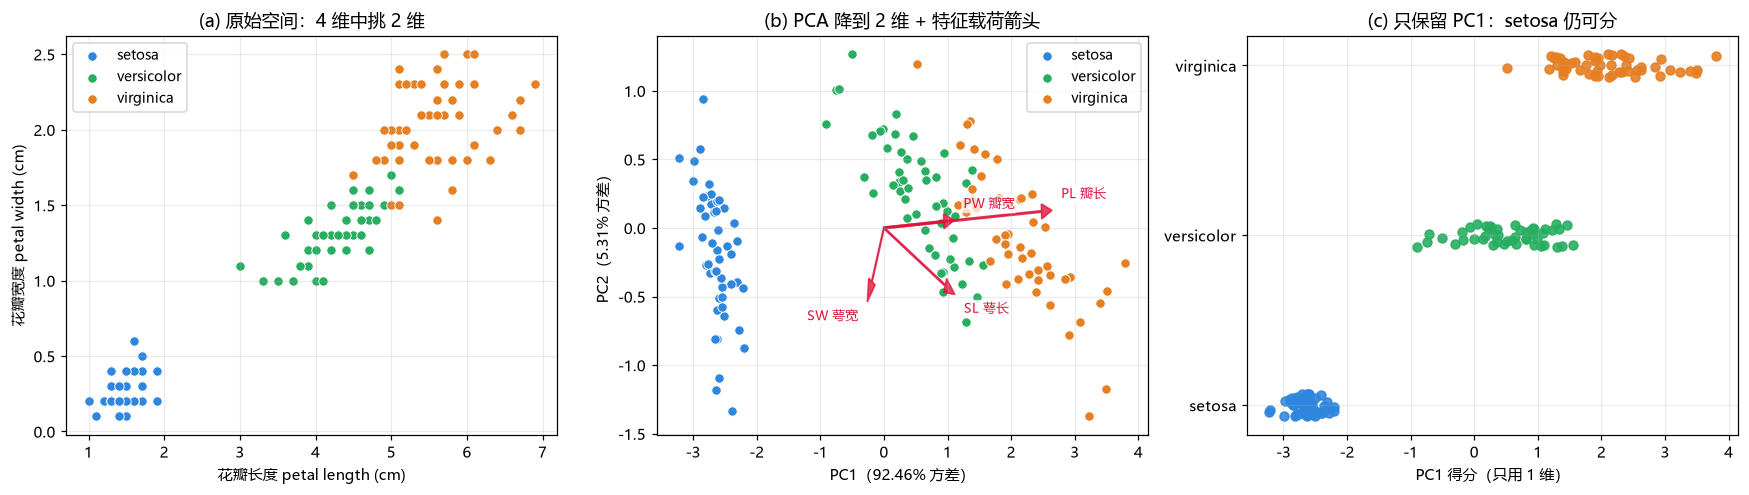

图已保存: images/02_pca_iris_2d.png


In [11]:
# ---------- 5.2 修正版可视化 1：原始空间 / PCA 空间 / 一维投影 ----------
colors = ["#2E86DE", "#27AE60", "#E67E22"]          # 三个类别用三种颜色
labels = [s.split()[0] if " " in s else s for s in iris.target_names]
labels = ["setosa", "versicolor", "virginica"]      # 直接用类别名更短

fig = plt.figure(figsize=(16, 4.6))

# (a) 原始空间：花瓣长 × 花瓣宽（4 维里最能分开的两维）
ax1 = fig.add_subplot(1, 3, 1)
for c in range(3):
    m = y == c
    ax1.scatter(X[m, 2], X[m, 3], s=38, c=colors[c], label=labels[c],
                edgecolors="white", linewidths=0.6)
ax1.set_xlabel("花瓣长度 petal length (cm)")
ax1.set_ylabel("花瓣宽度 petal width (cm)")
ax1.set_title("(a) 原始空间：4 维中挑 2 维")
ax1.legend(fontsize=9)

# (b) PCA 空间 + 双标图
ax2 = fig.add_subplot(1, 3, 2)
for c in range(3):
    m = y == c
    ax2.scatter(Y[m, 0], Y[m, 1], s=38, c=colors[c], label=labels[c],
                edgecolors="white", linewidths=0.6)
scale = 3.0                                          # 箭头长度只影响观感，不影响结论
short = ["SL 萼长", "SW 萼宽", "PL 瓣长", "PW 瓣宽"]   # 特征简写，避免文字互相压住
for j, fname in enumerate(iris.feature_names):
    vx = P[j, 0] * np.sqrt(vals[0]) * scale / 2
    vy = P[j, 1] * np.sqrt(vals[1]) * scale / 2
    ax2.arrow(0, 0, vx, vy, color="crimson", width=0.012,
              head_width=0.11, alpha=0.8, length_includes_head=True)
    ax2.annotate(short[j], xy=(vx, vy), xytext=(6 if vx >= 0 else -6, 8 if vy >= 0 else -12),
                 textcoords="offset points", fontsize=8.5, color="crimson",
                 ha="left" if vx >= 0 else "right",
                 bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax2.set_xlabel(f"PC1（{ratio[0]*100:.2f}% 方差）")
ax2.set_ylabel(f"PC2（{ratio[1]*100:.2f}% 方差）")
ax2.set_title("(b) PCA 降到 2 维 + 特征载荷箭头")
ax2.legend(fontsize=9)

# (c) 只保留 1 维：PC1 得分 + 类别（加了轻微抖动，避免点完全重叠）
ax3 = fig.add_subplot(1, 3, 3)
for c in range(3):
    m = y == c
    jitter = np.random.uniform(-0.07, 0.07, m.sum())
    ax3.scatter(Y[m, 0], np.full(m.sum(), c) + jitter, s=34,
                c=colors[c], alpha=0.9)
ax3.set_yticks([0, 1, 2])
ax3.set_yticklabels(labels)
ax3.set_xlabel("PC1 得分（只用 1 维）")
ax3.set_title("(c) 只保留 PC1：setosa 仍可分")
plt.tight_layout()
plt.savefig("images/02_pca_iris_2d.png", dpi=150, bbox_inches="tight")
plt.show()
print("图已保存: images/02_pca_iris_2d.png")

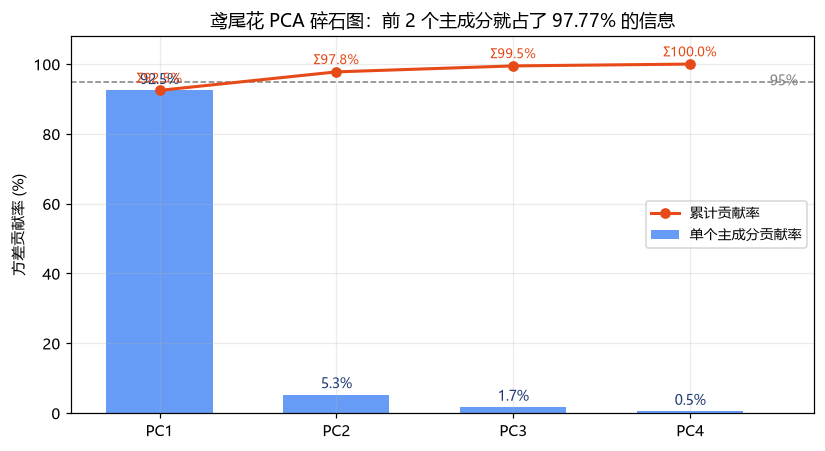

图已保存: images/03_scree_plot.png


In [12]:
# ---------- 5.3 碎石图（scree plot）+ 累计方差贡献 ----------
fig, ax = plt.subplots(figsize=(7.6, 4.2))
idx = np.arange(1, 5)

bars = ax.bar(idx, ratio * 100, color="#4C8BF5", alpha=0.85, width=0.6,
              label="单个主成分贡献率")
ax.plot(idx, np.cumsum(ratio) * 100, "o-", color="#E64A19", lw=2,
        label="累计贡献率", zorder=3)

for i, (r, cr) in enumerate(zip(ratio, np.cumsum(ratio))):
    ax.text(i + 1, r * 100 + 1.8, f"{r*100:.1f}%", ha="center", fontsize=9, color="#1f3b73")
    ax.text(i + 1, cr * 100 + 2.2, f"Σ{cr*100:.1f}%", ha="center", fontsize=8.5, color="#E64A19")

ax.axhline(95, ls="--", lw=1, color="gray")
ax.text(4.45, 95, "95%", color="gray", va="center", fontsize=9)
ax.set_xticks(idx)
ax.set_xticklabels([f"PC{i}" for i in idx])
ax.set_ylim(0, 108)
ax.set_xlim(0.5, 4.7)
ax.set_ylabel("方差贡献率 (%)")
ax.set_title("鸢尾花 PCA 碎石图：前 2 个主成分就占了 97.77% 的信息")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.savefig("images/03_scree_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("图已保存: images/03_scree_plot.png")

k | 整体 RMSE(cm) | 保留方差比 | 压缩率(存储)
1 |      0.292582 |   92.4619% |  25.0%
2 |      0.159189 |   97.7685% |  50.0%
3 |      0.076935 |   99.4788% |  75.0%
4 |      0.000000 |  100.0000% | 100.0%


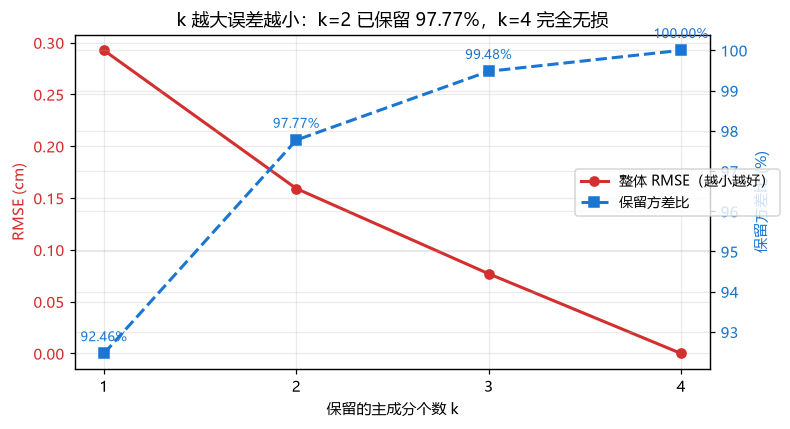

图已保存: images/04_k_vs_error.png


In [13]:
# ---------- 5.4 降维到 k 维时，信息损失有多大？ ----------
ks = [1, 2, 3, 4]
rmse_list, keep_list = [], []
for kk in ks:
    Pk = eigvec[:, order[:kk]]           # (4, k)
    Yk = Xc @ Pk                         # (150, k)
    Xk = Yk @ Pk.T + mu                  # 反投影回 4 维
    rmse_list.append(np.sqrt(((X - Xk) ** 2).mean()))                      # 整体 RMSE
    keep_list.append(1 - ((X - Xk) ** 2).sum() / ((X - mu) ** 2).sum())     # 保留方差比

print("k | 整体 RMSE(cm) | 保留方差比 | 压缩率(存储)")
for kk, r, cp in zip(ks, rmse_list, keep_list):
    # 降到 k 维需存 150×k 个数，原数据是 150×4 个数
    print(f"{kk} | {r:13.6f} | {cp*100:9.4f}% | {kk/4*100:5.1f}%")

fig, ax1 = plt.subplots(figsize=(7.2, 4.0))
ax1.plot(ks, rmse_list, "o-", color="#D32F2F", lw=2, label="整体 RMSE（越小越好）")
ax1.set_xlabel("保留的主成分个数 k")
ax1.set_ylabel("RMSE (cm)", color="#D32F2F")
ax1.tick_params(axis="y", labelcolor="#D32F2F")
ax1.set_xticks(ks)

ax2 = ax1.twinx()                                  # 共享 x 轴、独立 y 轴
ax2.plot(ks, np.array(keep_list) * 100, "s--", color="#1976D2", lw=2, label="保留方差比")
ax2.set_ylabel("保留方差比 (%)", color="#1976D2")
ax2.tick_params(axis="y", labelcolor="#1976D2")

for kk, cp in zip(ks, keep_list):
    ax2.annotate(f"{cp*100:.2f}%", (kk, cp * 100), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=8.5, color="#1976D2")

ax1.set_title("k 越大误差越小：k=2 已保留 97.77%，k=4 完全无损")
fig.legend(loc="center right", bbox_to_anchor=(1.0, 0.55), fontsize=9)
plt.tight_layout()
plt.savefig("images/04_k_vs_error.png", dpi=150, bbox_inches="tight")
plt.show()
print("图已保存: images/04_k_vs_error.png")

# 6. 与 `sklearn.decomposition.PCA` 交叉验证

自己写的 PCA 对不对，最直接的验证方式就是和成熟库比。要点：

- `sklearn` 的 `explained_variance_` 与我们对 `np.cov(ddof=1)` 求出的特征值**完全相等**；
- `explained_variance_ratio_` 与我们的 `ratio` 相等；
- 投影结果 `transform(X)` 与我们的 `Y` **可能整体差一个负号**（特征向量符号不唯一），取绝对值后应当一致。

In [14]:
# ---------- 6. sklearn 交叉验证 ----------
from sklearn.decomposition import PCA as SkPCA

sk = SkPCA(n_components=2, svd_solver="full").fit(X)
Ysk = sk.transform(X)

print("sklearn 解释方差（= 特征值）:", sk.explained_variance_)
print("手算   特征值（降序）       :", vals[:2])
print("特征值一致                  :", np.allclose(sk.explained_variance_, vals[:2]))

print("\nsklearn 方差贡献率 :", sk.explained_variance_ratio_)
print("手算   方差贡献率  :", ratio[:2])
print("贡献率一致         :", np.allclose(sk.explained_variance_ratio_, ratio[:2]))

print("\nsklearn components_（每一**行**是一个主成分）:\n", sk.components_)
print("手算 P 的转置（形状 2×4）:\n", P.T)

corr = [abs(np.corrcoef(Ysk[:, i], Y[:, i])[0, 1]) for i in range(2)]
print("\n逐列相关系数（1 = 完全同向/反向）:", np.round(corr, 8))
print("取绝对值后完全一致:", np.allclose(np.abs(Ysk), np.abs(Y), atol=1e-10))

# sklearn 用 SVD 求解，这里顺便看一眼：SVD 的奇异值 = 特征值的平方根
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
print("\nSVD 奇异值的平方/(n-1) :", S[:4] ** 2 / (Xc.shape[0] - 1))
print("与协方差特征值一致      :", np.allclose(S[:4] ** 2 / (Xc.shape[0] - 1), vals))

sklearn 解释方差（= 特征值）: [4.2282 0.2427]
手算   特征值（降序）       : [4.2282 0.2427]
特征值一致                  : True

sklearn 方差贡献率 : [0.9246 0.0531]
手算   方差贡献率  : [0.9246 0.0531]
贡献率一致         : True

sklearn components_（每一**行**是一个主成分）:
 [[ 0.3614 -0.0845  0.8567  0.3583]
 [ 0.6566  0.7302 -0.1734 -0.0755]]
手算 P 的转置（形状 2×4）:
 [[ 0.3614 -0.0845  0.8567  0.3583]
 [-0.6566 -0.7302  0.1734  0.0755]]

逐列相关系数（1 = 完全同向/反向）: [1. 1.]
取绝对值后完全一致: True

SVD 奇异值的平方/(n-1) : [4.2282 0.2427 0.0782 0.0238]
与协方差特征值一致      : True


# 7. 结论与踩坑清单

## 7.1 实验结论

| 指标 | 数值 | 含义 |
| --- | --- | --- |
| 均值向量 | `[5.8433, 3.0573, 3.7580, 1.1993]` | 4 个特征的中心 |
| 特征值 | `[4.2282, 0.2427, 0.0782, 0.0238]` | 每个主成分承载的方差 |
| PC1 贡献率 | **92.46%** | 主要反映「花瓣大小」（花瓣长/宽载荷都很大） |
| PC2 贡献率 | **5.31%** | 主要反映「花萼宽」（载荷为负） |
| k=2 累计 | **97.77%** | 4 维 → 2 维只丢 2.23% 的信息 |
| 重构 RMSE | ≈ 0.11 cm 量级 | 远小于特征本身的量级（1~6 cm），视觉上几乎无损 |

一句话：**鸢尾花的 4 个特征高度相关，本质上只有约 2 个独立方向**，所以降到 2 维几乎不损失信息，
而且降维后的 PC1/PC2 散点图上三个类别依然清晰可分（setosa 尤其干净）。

## 7.2 踩坑清单（按「会不会直接报错」排序）

| 坑 | 现象 | 正确做法 |
| --- | --- | --- |
| `np.mat(...)` / `np.matrix` | NumPy ≥ 2.0 直接 `AttributeError: module 'numpy' has no attribute 'mat'` | 用 `@` / `np.dot` / `A.dot(B)`；不要再用 `matrix` 类型 |
| `rowvar` 写反 | `np.cov(X)` 得到 150×150，特征分解又慢又没意义 | 数据是 `(样本, 特征)` 时写 `rowvar=0` |
| 忘记排序 | 取到的「前 k 个」是随便 k 个方向，贡献率可能只有 5% | `idx = np.argsort(-eigval)`；对称矩阵也可用 `eigh` 直接得到升序 |
| 特征向量按行取 | `fVector[:k].T` 取到的是错误方向 | `eig` 返回的特征向量**按列**存放：`fVector[:, idx[:k]]` |
| 特征向量符号 | 和 sklearn 结果整体差一个负号，以为算错了 | 符号不唯一，比较时取绝对值或看 `|corr|` |
| `*` 当矩阵乘法 | 二维数组 `*` 是逐元素乘，要么报 shape 错，要么算出错误结果 | 矩阵乘法用 `@` |
| 只中心化不标准化 | 量纲差别大时，方差大的特征垄断 PC1 | 特征量纲不同就先 `(X-μ)/σ`（`sklearn` 里 `StandardScaler`） |
| 混淆「降维」与「特征选择」 | 以为 PC1 就是原来的某个特征 | 主成分是**原始特征的线性组合**，一般不直接对应某个原始列 |
| 重构公式漏加均值 | 重建数据整体偏移、误差巨大 | $\hat X = Y P^\top + \mu$，均值一定要加回来 |
| 把 `target` 喂给 PCA | 无监督方法变成了「作弊」 | PCA 只用 `data`，`target` 仅用于画图/评估 |

## 7.3 还可以继续做的实验

1. 把 k 设成 1/3/4，观察重构误差与散点图的变化（本文件 5.4 已算数值）；
2. 故意给某个特征乘 100，观察不做标准化时 PC1 会被它垄断（见学习笔记里的对照实验）；
3. 用 `03_iris_pca_visualization.html` 在浏览器里交互式观察同一套结果；
4. 换成 `np.linalg.svd` 实现，对比数值稳定性（sklearn 内部用的就是 SVD）。